# Modelagem preditiva da produtividade da safra de soja com uso de aprendizado de máquina e dados agrometeorológicos — Modelagem (Etapa 4: balanço hídrico, combinação de modelos e adubação)

**Integrantes:**
**Orientador:**

**Síntese do conteúdo deste arquivo:** o modelo final da Etapa 3 (`modelagem_etapa3.ipynb`: patamar = média móvel de 5 anos do município + OLS reduzida com o clima por subperíodo) previu só cerca de metade da quebra nas secas mais severas (2020 e 2022). Este notebook (1) calcula um **balanço hídrico diário** por estação INMET (evapotranspiração de referência por Hargreaves-Samani e modelo de "balde" de água no solo), gerando o **déficit hídrico em dez–fev**; (2) testa **efeitos de limite** (perda adicional quando a seca passa de um nível extremo); (3) testa a **combinação** da OLS com o Gradient Boosting; e (4) usa o rendimento esperado de cada município com as tabelas da Embrapa/CQFS-RS/SC para gerar a **recomendação de adubação fosfatada e potássica por classe de teor do solo** para a safra 2026. Usa apenas dados já presentes no repositório e as mesmas duas validações da Etapa 3.

| Data       | Autor           | Descrição                                                                 |
|------------|-----------------|-----------------------------------------------------------------------------|
| 2026-10-22 |                 | Criação do notebook — balanço hídrico (Hargreaves-Samani + balde), limiares, combinação OLS + Gradient Boosting e recomendação de adubação por classe de solo |
| 2026-10-24 |                 | Patamar e adubação respeitam a defasagem de publicação da PAM/IBGE (última safra publicada em março de Y é Y−2); nova seção 9 mede o efeito dessa defasagem |

## 1. Imports e configuração

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RAW = "../dataset/raw"
PROCESSED = "../dataset/processed"

ANO_CORTE = 2020          # corte temporal: treino até 2020, teste 2021-2025
DEFASAGEM_PUBLICACAO = 2  # em março de Y, a última safra publicada pela PAM/IBGE é Y-2
PRIMEIRA_SAFRA = 2006     # primeira safra com 5 safras publicadas para o patamar
SEED = 42
COBERTURA_MINIMA = 0.8    # fração mínima de dias com dado (out–fev) por estação e safra
CAD_MM = 75               # capacidade de água disponível no solo (hipótese, ver seção 3)
CADS_SENSIBILIDADE = [50, 75, 100]
PERCENTIL_LIMIAR = 0.2    # limiares de seca extrema: 20% mais secos do treino

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print("Ambiente pronto.")

Ambiente pronto.


## 2. Dados

- Painel município–safra (rendimento, estação INMET associada, ONI);
- Clima por subperíodo por estação e safra, gerado na Etapa 2;
- INMET diário (chuva, temperatura máxima e mínima) e metadados das estações (latitude),
  para o balanço hídrico;
- Regiões dos municípios (IBGE) e tabelas de adubação da Embrapa/CQFS-RS/SC, para a
  seção de adubação.

In [2]:
painel = pd.read_csv(f"{PROCESSED}/painel_municipio_safra.csv")
clima_sub = pd.read_csv(f"{PROCESSED}/clima_subperiodos_estacao_safra.csv")
regioes = pd.read_csv(f"{RAW}/ibge_municipios_rs_regioes.csv",
                      usecols=["codigo_ibge_municipio", "mesorregiao"])
regioes["mesorregiao"] = regioes["mesorregiao"].str.replace(" Rio-grandense", "")

ALVO = "rendimento_kg_ha"
ONI = "oni_media_safra"
CLIMA = ["chuva_out_nov", "chuva_dez_fev", "chuva_mar", "seca_max_dez_fev",
         "dias_calor_dez_fev", "tmax_dez_fev", "urmin_dez_fev"]
com_rendimento = painel.dropna(subset=[ALVO])
print(f"Linhas com rendimento: {len(com_rendimento)}")

Linhas com rendimento: 10540


## 3. Balanço hídrico diário (out–fev)

O total de chuva e a umidade do ar não medem diretamente o que importa para a planta:
**faltou água no solo?** O balanço hídrico estima isso dia a dia.

**Evapotranspiração de referência (ETo)** — quanto de água a superfície perderia por
dia se não faltasse água. Calculada pelo método de **Hargreaves-Samani**, recomendado
pela FAO (Allen et al., 1998, *FAO-56*) quando não há medição de radiação solar, como
no arquivo do INMET usado aqui:

ETo = 0,0023 × 0,408·Ra × (Tmédia + 17,8) × √(Tmáx − Tmín)

em que Ra é a radiação no topo da atmosfera, **calculada por fórmula** a partir da
latitude da estação e do dia do ano (FAO-56, eq. 21) — não é um dado medido.

**Modelo de "balde"** — o solo é um reservatório com capacidade de **75 mm** de água
disponível (CAD). A cada dia: entra a chuva, sai a evapotranspiração; se o balde
esvazia, a planta não consegue transpirar tudo o que precisaria, e a diferença é o
**déficit hídrico** do dia. O balde começa cheio em 1º de outubro (fim do inverno
chuvoso no RS).

Variáveis geradas por estação e safra:

- `deficit_dez_fev` — soma do déficit hídrico diário em dez–fev (mm): quanto de água a
  lavoura deixou de ter no período crítico;
- `balanco_dez_fev` — chuva − ETo acumulado em dez–fev (mm), sem o solo;
- `eto_dez_fev` — ETo acumulada em dez–fev (mm), a "demanda" de água da atmosfera.

**Hipóteses a declarar no artigo:** (a) CAD fixa de 75 mm para todo o estado, valor
intermediário para a zona de raízes da soja — sem base de solos por município, a
sensibilidade a esse valor é testada abaixo (50 e 100 mm); (b) coeficiente de cultura
igual a 1 (a demanda da soja é aproximada pela ETo); (c) dias sem dado são preenchidos
com a média da mesma estação, safra e mês, e a estação-safra só é usada se tiver dado em
pelo menos 80% dos dias de out–fev.

In [3]:
colunas = {"Codigo Estacao": "estacao", "Data Medicao": "data",
           "PRECIPITACAO TOTAL, DIARIO (AUT)(mm)": "chuva",
           "TEMPERATURA MAXIMA, DIARIA (AUT)(°C)": "tmax",
           "TEMPERATURA MINIMA, DIARIA (AUT)(°C)": "tmin"}
diario = (pd.read_csv(f"{RAW}/inmet_estacoes_RS_consolidado_2000_2025.csv", sep=";",
                      dtype=str, usecols=list(colunas))
          .rename(columns=colunas))
diario["data"] = pd.to_datetime(diario["data"])
for c in ["chuva", "tmax", "tmin"]:
    diario[c] = pd.to_numeric(diario[c].str.replace(",", "."), errors="coerce")
diario = diario.drop_duplicates(["estacao", "data"])

calendario = pd.MultiIndex.from_product(
    [diario["estacao"].unique(), pd.date_range("2000-10-01", "2025-02-28")],
    names=["estacao", "data"])
diario = diario.set_index(["estacao", "data"]).reindex(calendario).reset_index()
diario = diario[diario["data"].dt.month.isin([10, 11, 12, 1, 2])].copy()
diario["mes"] = diario["data"].dt.month
diario["ano_safra"] = diario["data"].dt.year + (diario["mes"] >= 10)

latitude = (pd.read_csv(f"{RAW}/inmet_estacoes_metadados.csv", sep=";",
                        usecols=["Codigo Estacao", "Latitude"])
            .set_index("Codigo Estacao")["Latitude"])
phi = np.radians(diario["estacao"].map(latitude))

# Radiação no topo da atmosfera, Ra (MJ m-2 dia-1) — FAO-56, eq. 21-25
J = diario["data"].dt.dayofyear
dr = 1 + 0.033 * np.cos(2 * np.pi * J / 365)
delta = 0.409 * np.sin(2 * np.pi * J / 365 - 1.39)
ws = np.arccos(-np.tan(phi) * np.tan(delta))
Ra = (24 * 60 / np.pi) * 0.0820 * dr * (ws * np.sin(phi) * np.sin(delta)
                                         + np.cos(phi) * np.cos(delta) * np.sin(ws))

# ETo de Hargreaves-Samani (mm/dia)
amplitude = (diario["tmax"] - diario["tmin"]).clip(lower=0)
diario["eto"] = 0.0023 * 0.408 * Ra * ((diario["tmax"] + diario["tmin"]) / 2 + 17.8) * np.sqrt(amplitude)

chave = ["estacao", "ano_safra"]
cobertura = diario.groupby(chave)[["chuva", "eto"]].count().div(diario.groupby(chave).size(), axis=0)
validas = cobertura[(cobertura >= COBERTURA_MINIMA).all(axis=1)].index

# Preenche falhas com a média da estação na mesma safra e mês
for c in ["chuva", "eto"]:
    diario[c] = diario[c].fillna(diario.groupby(chave + ["mes"])[c].transform("mean"))

print(f"Dias-estação (out–fev): {len(diario):,} | estação × safra válidas: {len(validas)} "
      f"de {len(cobertura)}")
print(f"ETo média em dez–fev: {diario.loc[diario['mes'].isin([12, 1, 2]), 'eto'].mean():.1f} mm/dia")

Dias-estação (out–fev): 170,145 | estação × safra válidas: 638 de 1125
ETo média em dez–fev: 5.4 mm/dia


In [4]:
def balanco_hidrico(cad):
    # Modelo de balde diário por estação; devolve o déficit acumulado em dez–fev
    partes = []
    for ano, g in diario.groupby("ano_safra"):
        P = g.pivot(index="data", columns="estacao", values="chuva").sort_index()
        E = g.pivot(index="data", columns="estacao", values="eto").reindex_like(P)
        armazenado = np.full(P.shape[1], float(cad))
        deficit = np.empty(P.shape)
        for i, (p, e) in enumerate(zip(P.to_numpy(), E.to_numpy())):
            disponivel = armazenado + p
            etr = np.minimum(e, disponivel)          # evapotranspiração real
            deficit[i] = e - etr
            armazenado = np.minimum(cad, disponivel - etr)
        dez_fev = P.index.month.isin([12, 1, 2])
        partes.append(pd.DataFrame({"codigo_estacao": P.columns, "ano_safra": ano,
                                    "deficit_dez_fev": deficit[dez_fev].sum(axis=0)}))
    return pd.concat(partes, ignore_index=True)


dez_fev = diario[diario["mes"].isin([12, 1, 2])]
hidrico = (dez_fev.assign(balanco=dez_fev["chuva"] - dez_fev["eto"])
           .groupby(chave)[["balanco", "eto"]].sum()
           .rename(columns={"balanco": "balanco_dez_fev", "eto": "eto_dez_fev"}))
hidrico = hidrico.loc[hidrico.index.intersection(validas)].reset_index()
hidrico = hidrico.rename(columns={"estacao": "codigo_estacao"})

deficits = {cad: balanco_hidrico(cad) for cad in CADS_SENSIBILIDADE}
for cad, d in deficits.items():
    hidrico = hidrico.merge(d.rename(columns={"deficit_dez_fev": f"deficit_cad{cad}"}),
                            on=["codigo_estacao", "ano_safra"], how="left")
hidrico["deficit_dez_fev"] = hidrico[f"deficit_cad{CAD_MM}"]
print(f"Estação × safra com balanço hídrico: {len(hidrico)}")
hidrico.groupby("ano_safra")[["deficit_dez_fev", "balanco_dez_fev", "eto_dez_fev"]].mean().loc[2017:].round(0)

Estação × safra com balanço hídrico: 638


,deficit_dez_fev,balanco_dez_fev,eto_dez_fev
ano_safra,,,
2017,101.00,-22.00,472.00
2018,172.00,-136.00,487.00
2019,95.00,17.00,470.00
2020,252.00,-241.00,513.00
2021,101.00,-33.00,469.00
2022,330.00,-305.00,536.00
2023,301.00,-283.00,521.00
2024,89.00,-32.00,473.00
2025,199.00,-175.00,507.00


## 4. Patamar, linha de base e base de modelagem

Mesmo patamar do modelo final da Etapa 3 (média do rendimento do município nas 5 últimas
safras **publicadas**, com mínimo de 3; senão, média estadual) e a linha de base "média
histórica" (todas as safras publicadas).

**Só entra o que já foi publicado na data da previsão.** A PAM/IBGE divulga o rendimento
municipal em setembro do ano seguinte à colheita, então em março de *Y* a última safra
disponível é **Y−2** (ver seção 3 de `modelagem_etapa3.ipynb`). Para prever 2026, o
patamar é a média de 2020–2024; para 2027, de 2021–2025; para 2028, de 2022–2026.

Também é calculado o patamar com **Y−1** (`patamar_mm5_d1`, `base_media_hist_d1`). Ele
não é usado nos modelos: serve só para a seção 9 medir quanto o desempenho depende
dessa defasagem.

In [5]:
rend = com_rendimento.pivot_table(index="ano_safra", columns="codigo_ibge_municipio", values=ALVO)
estado = rend.mean(axis=1)


def calcular_patamares(defasagem, sufixo=""):
    # Patamar e média histórica da safra `ano` com as safras publicadas até `ano - defasagem`
    partes = []
    for ano in range(PRIMEIRA_SAFRA, int(rend.index.max()) + 1):
        ultima = ano - defasagem
        j5, todos = rend.loc[ultima - 4:ultima], rend.loc[:ultima]
        partes.append(pd.DataFrame({
            "ano_safra": ano,
            f"patamar_mm5{sufixo}": j5.mean().where(j5.count() >= 3, estado.loc[ultima - 4:ultima].mean()),
            f"base_media_hist{sufixo}": todos.mean().where(todos.count() >= 3, estado.loc[:ultima].mean()),
        }))
    return pd.concat(partes).rename_axis("codigo_ibge_municipio").reset_index()


patamares = calcular_patamares(DEFASAGEM_PUBLICACAO).merge(
    calcular_patamares(1, "_d1"), on=["codigo_ibge_municipio", "ano_safra"])

VAR_HIDRICO = ["deficit_dez_fev", "balanco_dez_fev", "eto_dez_fev"]
base = (painel.merge(clima_sub, on=["codigo_estacao", "ano_safra"], how="left")
        .merge(hidrico, on=["codigo_estacao", "ano_safra"], how="left")
        .merge(patamares, on=["codigo_ibge_municipio", "ano_safra"], how="left"))
base = base.dropna(subset=[ALVO, ONI, "patamar_mm5", "base_media_hist"] + CLIMA + VAR_HIDRICO)
base = base[base["ano_safra"] >= PRIMEIRA_SAFRA].copy()
base["desvio"] = base[ALVO] - base["patamar_mm5"]
print(f"Linhas: {len(base)} | municípios: {base['codigo_ibge_municipio'].nunique()} | "
      f"treino (<= {ANO_CORTE}): {(base['ano_safra'] <= ANO_CORTE).sum()} | "
      f"teste: {(base['ano_safra'] > ANO_CORTE).sum()}")

Linhas: 5236 | municípios: 448 | treino (<= 2020): 3645 | teste: 1591


### O déficit hídrico explica o desvio do rendimento? (e sensibilidade à CAD)

Correlação do desvio (rendimento − patamar) com cada variável de seca. Se a escolha da
CAD fosse decisiva, as correlações com 50, 75 e 100 mm seriam muito diferentes.

,correlação com o desvio
deficit_cad50,-0.61
deficit_cad75,-0.62
deficit_cad100,-0.62
balanco_dez_fev,0.57
eto_dez_fev,-0.44
chuva_dez_fev,0.52
urmin_dez_fev,0.54
dias_calor_dez_fev,-0.38


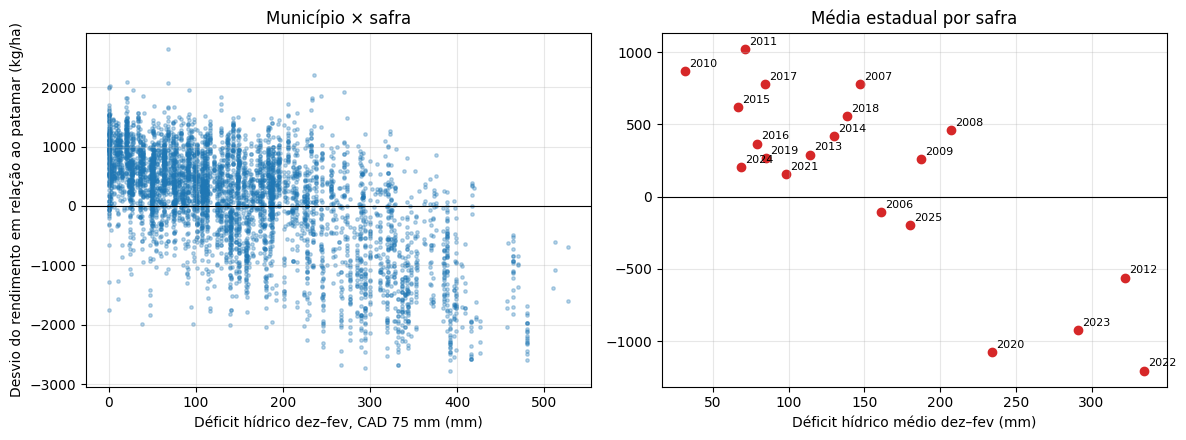

In [6]:
candidatas = ([f"deficit_cad{c}" for c in CADS_SENSIBILIDADE]
              + ["balanco_dez_fev", "eto_dez_fev", "chuva_dez_fev", "urmin_dez_fev",
                 "dias_calor_dez_fev"])
correl = base[candidatas].corrwith(base["desvio"]).rename("correlação com o desvio")
display(correl.round(3).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(base["deficit_dez_fev"], base["desvio"], s=6, alpha=0.3)
axes[0].set_xlabel(f"Déficit hídrico dez–fev, CAD {CAD_MM} mm (mm)")
axes[0].set_ylabel("Desvio do rendimento em relação ao patamar (kg/ha)")
axes[0].set_title("Município × safra")
por_ano = base.groupby("ano_safra")[["deficit_dez_fev", "desvio"]].mean()
axes[1].scatter(por_ano["deficit_dez_fev"], por_ano["desvio"], color="tab:red")
for ano, r in por_ano.iterrows():
    axes[1].annotate(str(ano), (r["deficit_dez_fev"], r["desvio"]), fontsize=8,
                     xytext=(3, 3), textcoords="offset points")
axes[1].set_xlabel("Déficit hídrico médio dez–fev (mm)")
axes[1].set_title("Média estadual por safra")
for ax in axes:
    ax.axhline(0, color="k", lw=0.8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Modelos

Todos partem do mesmo patamar (média móvel de 5 anos) e preveem o desvio em relação a
ele, exceto a linha de base.

| Modelo | Variáveis do desvio |
|---|---|
| **Linha de base: média histórica** | — (sem clima) |
| **F — Final da Etapa 3** | chuva out–nov, chuva dez–fev (+ quadrado), chuva mar, dias de calor dez–fev, umidade mín. dez–fev |
| **H1 — F + déficit hídrico** | as de F + déficit hídrico dez–fev |
| **H2 — H1 + limiares** | as de H1 + dois termos de seca extrema: quanto a umidade mínima ficou **abaixo** do nível dos 20% safras mais secas do treino, e quanto o déficit ficou **acima** do nível dos 20% mais secos. Esses termos valem zero em safras normais e só "ligam" na seca forte, permitindo que a perda cresça mais rápido nesses casos |
| **GB — Gradient Boosting hídrico** | todas as variáveis climáticas, o ONI e as três variáveis do balanço hídrico |
| **Combinação (H2 + GB)** | média simples das previsões de H2 e GB, definida antes de ver os resultados |

Os limiares são calculados só com os dados de treino de cada rodada.

In [7]:
FEAT_F = ["chuva_out_nov_100", "chuva_dez_fev_c100", "chuva_dez_fev_c100_2", "chuva_mar_100",
          "dias_calor_dez_fev", "urmin_dez_fev"]
FEAT_H1 = FEAT_F + ["deficit_100"]
FEAT_H2 = FEAT_H1 + ["limiar_urmin", "limiar_deficit_100"]
FEAT_GB = CLIMA + [ONI] + VAR_HIDRICO


def derivar(d, ref):
    d = d.copy()
    d["chuva_out_nov_100"] = d["chuva_out_nov"] / 100
    d["chuva_dez_fev_c100"] = (d["chuva_dez_fev"] - ref["chuva"]) / 100
    d["chuva_dez_fev_c100_2"] = d["chuva_dez_fev_c100"] ** 2
    d["chuva_mar_100"] = d["chuva_mar"] / 100
    d["deficit_100"] = d["deficit_dez_fev"] / 100
    d["limiar_urmin"] = (ref["urmin"] - d["urmin_dez_fev"]).clip(lower=0)
    d["limiar_deficit_100"] = (d["deficit_dez_fev"] - ref["deficit"]).clip(lower=0) / 100
    return d


def referencias(tr):
    return {"chuva": tr["chuva_dez_fev"].mean(),
            "urmin": tr["urmin_dez_fev"].quantile(PERCENTIL_LIMIAR),
            "deficit": tr["deficit_dez_fev"].quantile(1 - PERCENTIL_LIMIAR)}


def gb():
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=500, min_samples_leaf=20,
                                         early_stopping=True, validation_fraction=0.1,
                                         random_state=SEED)


MODELOS = ["Linha de base: média histórica", "F - Final Etapa 3", "H1 - F + déficit hídrico",
           "H2 - H1 + limiares", "GB - Gradient Boosting hídrico", "Combinação (H2 + GB)"]


def prever_todos(tr, te):
    ref = referencias(tr)
    tr, te = derivar(tr, ref), derivar(te, ref)
    pat = te["patamar_mm5"].to_numpy()
    saida = {"Linha de base: média histórica": te["base_media_hist"].to_numpy()}
    for nome, feats in [("F - Final Etapa 3", FEAT_F), ("H1 - F + déficit hídrico", FEAT_H1),
                        ("H2 - H1 + limiares", FEAT_H2)]:
        saida[nome] = pat + LinearRegression().fit(tr[feats], tr["desvio"]).predict(te[feats])
    saida["GB - Gradient Boosting hídrico"] = pat + gb().fit(tr[FEAT_GB], tr["desvio"]).predict(te[FEAT_GB])
    saida["Combinação (H2 + GB)"] = (saida["H2 - H1 + limiares"] + saida["GB - Gradient Boosting hídrico"]) / 2
    return saida


def metricas(y, pred):
    return {"RMSE (kg/ha)": mean_squared_error(y, pred) ** 0.5,
            "MAE (kg/ha)": mean_absolute_error(y, pred),
            "R²": r2_score(y, pred),
            "Viés (kg/ha)": np.mean(pred - y)}


FORMATO = {"RMSE (kg/ha)": "{:.0f}", "MAE (kg/ha)": "{:.0f}", "R²": "{:.3f}",
           "Viés (kg/ha)": "{:+.0f}", "RMSE vs F": "{:+.1%}"}


def tabela(y, previsoes):
    t = pd.DataFrame({n: metricas(y, previsoes[n]) for n in MODELOS}).T
    t["RMSE vs F"] = t["RMSE (kg/ha)"] / t.loc["F - Final Etapa 3", "RMSE (kg/ha)"] - 1
    return t


ref_total = referencias(base)
print(f"Limiares (base inteira, ilustrativo): umidade mínima < {ref_total['urmin']:.1f}% | "
      f"déficit > {ref_total['deficit']:.0f} mm")

Limiares (base inteira, ilustrativo): umidade mínima < 41.6% | déficit > 238 mm


## 6. Validação 1 — corte temporal (treino até 2020, teste 2021–2025)

In [8]:
treino = base[base["ano_safra"] <= ANO_CORTE]
teste = base[base["ano_safra"] > ANO_CORTE]
prev_corte = prever_todos(treino, teste)
corte = tabela(teste[ALVO], prev_corte)
print(f"Teste: {len(teste)} linhas | rendimento médio {teste[ALVO].mean():.0f} kg/ha")
corte.style.format(FORMATO).highlight_min(subset=["RMSE (kg/ha)"], color="#c6efce")

C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] O sistema não pode encontrar o arquivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\LENOVO\AppData\Local\Programs\Python\Python313\Lib\subprocess.

Teste: 1591 linhas | rendimento médio 2497 kg/ha


,RMSE (kg/ha),MAE (kg/ha),R²,Viés (kg/ha),RMSE vs F
Linha de base: média histórica,857,729,0.078,-145,-1.8%
F - Final Etapa 3,873,697,0.043,+498,+0.0%
H1 - F + déficit hídrico,902,734,-0.022,+526,+3.3%
H2 - H1 + limiares,870,716,0.049,+501,-0.3%
GB - Gradient Boosting hídrico,939,750,-0.108,+595,+7.6%
Combinação (H2 + GB),891,719,0.003,+548,+2.1%


## 7. Validação 2 — deixa uma safra de fora (2008–2025)

In [9]:
anos_loyo = [a for a in sorted(base["ano_safra"].unique()) if a >= 2008]
partes = []
for ano in anos_loyo:
    tr, te = base[base["ano_safra"] != ano], base[base["ano_safra"] == ano]
    partes.append(te[["codigo_ibge_municipio", "ano_safra", ALVO, "patamar_mm5"]]
                  .assign(**prever_todos(tr, te)))
loyo = pd.concat(partes, ignore_index=True)
geral = tabela(loyo[ALVO], {n: loyo[n].to_numpy() for n in MODELOS})
print(f"{len(anos_loyo)} safras, {len(loyo)} linhas")
geral.style.format(FORMATO).highlight_min(subset=["RMSE (kg/ha)"], color="#c6efce")

18 safras, 5125 linhas


,RMSE (kg/ha),MAE (kg/ha),R²,Viés (kg/ha),RMSE vs F
Linha de base: média histórica,901,783,-0.279,-484,+26.1%
F - Final Etapa 3,714,560,0.196,+41,+0.0%
H1 - F + déficit hídrico,712,559,0.201,+40,-0.3%
H2 - H1 + limiares,706,553,0.214,+34,-1.2%
GB - Gradient Boosting hídrico,753,589,0.106,+121,+5.4%
Combinação (H2 + GB),705,552,0.215,+78,-1.2%


## 8. Resumo e escolha do modelo final

Mesmo critério da Etapa 3: menor média do RMSE nas duas validações.

In [10]:
resumo = pd.concat({"Corte 2021–2025": corte[["RMSE (kg/ha)", "R²", "Viés (kg/ha)"]],
                    "Deixa uma safra de fora": geral[["RMSE (kg/ha)", "R²", "Viés (kg/ha)"]]},
                   axis=1)
resumo[("Média", "RMSE (kg/ha)")] = resumo.xs("RMSE (kg/ha)", axis=1, level=1).mean(axis=1)
resumo = resumo.sort_values(("Média", "RMSE (kg/ha)"))
FINAL = resumo.index[0]
print("Modelo final (menor RMSE médio):", FINAL)
resumo.style.format("{:.0f}").format("{:.3f}", subset=[c for c in resumo.columns if c[1] == "R²"])

Modelo final (menor RMSE médio): H2 - H1 + limiares


## 9. Quanto custa respeitar a defasagem de publicação?

Os modelos acima usam o patamar com as safras publicadas até **Y−2**, que é o que existe
de fato em março de *Y*. Aqui eles são reavaliados, nas mesmas linhas e com as mesmas
validações, com o patamar até **Y−1**, como se o rendimento da safra anterior já
estivesse disponível em março. A diferença mostra quanto do desempenho viria dessa
informação.

O cenário Y−1 **não é uma previsão possível** com a PAM. Ele só representa o que se
ganharia com uma estimativa antecipada da safra anterior por município (por exemplo, um
levantamento estadual próprio), e serve como teto de comparação.

In [11]:
COMPARAR = ["Linha de base: média histórica", "F - Final Etapa 3", FINAL]
COMPARAR = list(dict.fromkeys(COMPARAR))
base_d1 = base.assign(patamar_mm5=base["patamar_mm5_d1"], base_media_hist=base["base_media_hist_d1"],
                      desvio=base[ALVO] - base["patamar_mm5_d1"])

corte_d1 = tabela(teste[ALVO], prever_todos(base_d1[base_d1["ano_safra"] <= ANO_CORTE],
                                            base_d1[base_d1["ano_safra"] > ANO_CORTE]))
partes = []
for ano in anos_loyo:
    tr, te = base_d1[base_d1["ano_safra"] != ano], base_d1[base_d1["ano_safra"] == ano]
    partes.append(te[[ALVO]].assign(**prever_todos(tr, te)))
loyo_d1 = pd.concat(partes, ignore_index=True)
geral_d1 = tabela(loyo_d1[ALVO], {n: loyo_d1[n].to_numpy() for n in MODELOS})

defasagem = pd.concat({
    ("Corte 2021–2025", "Y−2 (publicado)"): corte.loc[COMPARAR, ["RMSE (kg/ha)", "R²", "Viés (kg/ha)"]],
    ("Corte 2021–2025", "Y−1 (hipotético)"): corte_d1.loc[COMPARAR, ["RMSE (kg/ha)", "R²", "Viés (kg/ha)"]],
    ("Deixa uma safra de fora", "Y−2 (publicado)"): geral.loc[COMPARAR, ["RMSE (kg/ha)", "R²", "Viés (kg/ha)"]],
    ("Deixa uma safra de fora", "Y−1 (hipotético)"): geral_d1.loc[COMPARAR, ["RMSE (kg/ha)", "R²", "Viés (kg/ha)"]],
}, axis=1)
defasagem.style.format("{:.0f}").format("{:.3f}", subset=[c for c in defasagem.columns if c[2] == "R²"])


## 10. As secas severas foram melhor previstas?

Era o principal problema da Etapa 3. Para cada safra (prevista sem ser vista, na
validação "deixa uma safra de fora"), comparamos o desvio médio estadual em relação ao
patamar: observado × previsto pelo modelo da Etapa 3 (F) e pelo modelo final desta
etapa. A coluna "% da quebra captada" mostra quanto da queda observada o modelo previu.

Diferente da decomposição da seção 11 da Etapa 3 (modelo ajustado com todas as safras,
inclusive a explicada), aqui cada safra é prevista **sem ter sido vista** — é a medida
honesta de quanto o modelo antecipa uma quebra.

In [12]:
# Clima médio das safras de quebra, comparado a safras normais
base.groupby("ano_safra")[["desvio", "chuva_out_nov", "chuva_dez_fev", "deficit_dez_fev",
                           "urmin_dez_fev", "dias_calor_dez_fev", "chuva_mar"]].mean() \
    .loc[[2012, 2019, 2020, 2021, 2022, 2023]].round(0)

,desvio,chuva_out_nov,chuva_dez_fev,deficit_dez_fev,urmin_dez_fev,dias_calor_dez_fev,chuva_mar
ano_safra,,,,,,,
2012,-560.00,252.00,216.00,322.00,40.00,30.00,66.00
2019,267.00,392.00,467.00,85.00,50.00,25.00,146.00
2020,"-1,075.00",443.00,304.00,234.00,42.00,27.00,28.00
2021,156.00,138.00,437.00,98.00,48.00,15.00,138.00
2022,"-1,205.00",228.00,244.00,334.00,37.00,45.00,221.00
2023,-926.00,191.00,267.00,291.00,38.00,38.00,114.00


,observado,F - Final Etapa 3,H2 - H1 + limiares,% da quebra captada — F - Final Etapa 3,% da quebra captada — H2 - H1 + limiares
ano_safra,,,,,
2012,-560,-762,-856,136%,153%
2020,-1075,-85,-76,8%,7%
2022,-1205,-421,-572,35%,47%
2023,-926,-480,-570,52%,62%


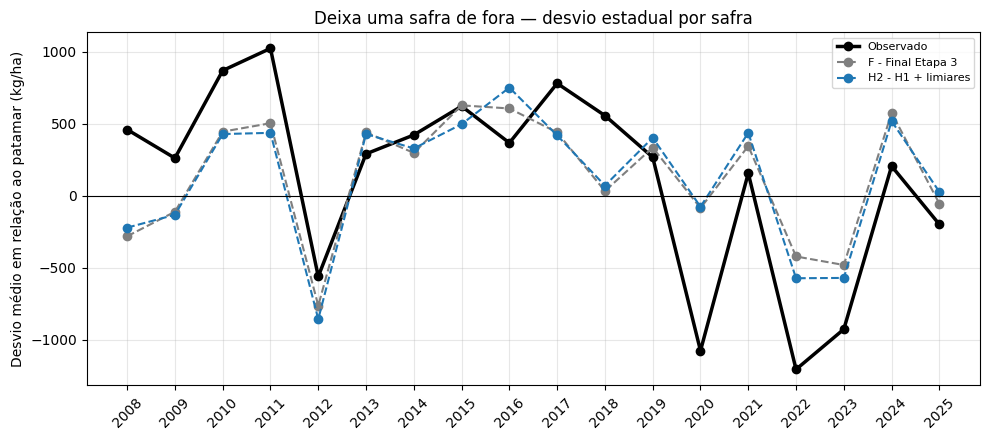

In [13]:
desvios = loyo.assign(**{n: loyo[n] - loyo["patamar_mm5"] for n in MODELOS},
                      observado=loyo[ALVO] - loyo["patamar_mm5"])
por_safra = desvios.groupby("ano_safra")[["observado", "F - Final Etapa 3", FINAL]].mean()
por_safra = por_safra.loc[:, ~por_safra.columns.duplicated()]
secas = por_safra.loc[[2012, 2020, 2022, 2023]].copy()   # as quatro maiores quebras do período
for col in por_safra.columns[1:]:
    secas[f"% da quebra captada — {col}"] = secas[col] / secas["observado"]
display(secas.style.format("{:.0f}").format("{:.0%}", subset=[c for c in secas.columns if c.startswith("%")]))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(por_safra.index, por_safra["observado"], "k-o", lw=2.5, label="Observado")
for col, cor in zip(por_safra.columns[1:], ["tab:grey", "tab:blue"]):
    ax.plot(por_safra.index, por_safra[col], "--o", color=cor, label=col)
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(por_safra.index)
ax.tick_params(axis="x", rotation=45)
ax.set_ylabel("Desvio médio em relação ao patamar (kg/ha)")
ax.set_title("Deixa uma safra de fora — desvio estadual por safra")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 11. Coeficientes da OLS com balanço hídrico e limiares (H2)

Ajustada com todas as safras da base. Mesmas ressalvas sobre os p-valores das etapas
anteriores.

In [14]:
def tabela_ols(modelo, X, y):
    Xc = np.column_stack([np.ones(len(X)), X.to_numpy(dtype=float)])
    beta = np.r_[modelo.intercept_, modelo.coef_]
    residuos = y.to_numpy() - Xc @ beta
    gl = len(y) - Xc.shape[1]
    ep = np.sqrt(np.diag(residuos @ residuos / gl * np.linalg.inv(Xc.T @ Xc)))
    t = beta / ep
    return pd.DataFrame({"coeficiente": beta, "erro_padrao": ep, "t": t,
                         "p_valor": 2 * stats.t.sf(np.abs(t), gl)},
                        index=["intercepto"] + list(X.columns))


completa = derivar(base, ref_total)
ols_h2 = LinearRegression().fit(completa[FEAT_H2], completa["desvio"])
print("Correlação entre déficit hídrico e chuva dez–fev:",
      f"{completa['deficit_dez_fev'].corr(completa['chuva_dez_fev']):+.2f} | "
      f"entre déficit e umidade mínima: {completa['deficit_dez_fev'].corr(completa['urmin_dez_fev']):+.2f}")
tabela_ols(ols_h2, completa[FEAT_H2], completa["desvio"])

Correlação entre déficit hídrico e chuva dez–fev: -0.79 | entre déficit e umidade mínima: -0.78


,coeficiente,erro_padrao,t,p_valor
intercepto,-208.58,142.11,-1.47,0.14
chuva_out_nov_100,-18.95,5.22,-3.63,0.00
chuva_dez_fev_c100,99.02,14.14,7.00,0.00
chuva_dez_fev_c100_2,-8.65,3.49,-2.48,0.01
chuva_mar_100,73.98,12.39,5.97,0.00
dias_calor_dez_fev,-0.12,0.79,-0.15,0.88
urmin_dez_fev,13.39,2.51,5.34,0.00
deficit_100,-154.72,25.56,-6.05,0.00
limiar_urmin,-40.72,6.65,-6.13,0.00
limiar_deficit_100,-237.73,43.39,-5.48,0.00


**Como ler:** `deficit_100` é o efeito de +100 mm de déficit hídrico em dez–fev em
safras normais; `limiar_deficit_100` é a perda **adicional** a cada 100 mm de déficit
acima do limiar de seca extrema; `limiar_urmin` é a perda adicional por ponto percentual
de umidade mínima abaixo do limiar. Como o déficit, a chuva e a umidade de dez–fev medem
a mesma seca por caminhos diferentes, os coeficientes individuais devem ser lidos em
conjunto.

## 12. Aplicação: recomendação de adubação fosfatada e potássica para a safra 2026

A adubação é decidida **no plantio** (out–nov), antes de se conhecer o clima do verão.
Por isso, o rendimento esperado usado aqui é o **patamar do modelo** — a média do
rendimento do município nas safras 2020–2024 (mínimo de 3) —, e não a previsão de março.
No plantio da safra 2026 (out–nov/2025), a última PAM publicada é a de 2024 (set/2025); o
rendimento de 2025 só sai em set/2026. Para a safra 2027 a janela passa a 2021–2025, e
assim por diante (`SAFRA_ADUBACAO - DEFASAGEM_PUBLICACAO`).

A recomendação segue a Tabela 2.4 da Embrapa/CQFS-RS/SC (`dataset/raw/embrapa_tabela_2.4_recomendacao_p2o5_k2o_soja.csv`):

- a tabela dá a dose de P₂O₅ e K₂O (kg/ha) por **classe de teor do nutriente no solo**
  para um rendimento de **2 t/ha**, no 1º e no 2º cultivo após a adubação corretiva;
- para rendimentos maiores, somam-se **15 kg/ha de P₂O₅ e 25 kg/ha de K₂O por tonelada
  adicional** — aplicado aqui de forma proporcional (ex.: 3,4 t/ha → +1,4 t);
- onde a tabela indica dose zero (classe "Muito alto", 1º cultivo), a dose foi mantida em
  zero; e rendimentos esperados abaixo de 2 t/ha usam a dose da tabela, sem redução.
  Essas duas regras são interpretações do grupo e devem ser declaradas.

**Nenhuma suposição sobre o solo é feita:** a recomendação é dada para as cinco classes,
e o produtor escolhe a linha pela própria análise de solo, usando a Tabela 2.3 abaixo.

### Como identificar a classe do solo (Tabela 2.3)

O teor de fósforo (P, Mehlich-1) é interpretado conforme a **classe textural** do solo
(teor de argila: classe 1 > 60%; classe 2: 41–60%; classe 3: 21–40%; classe 4: ≤ 20%), e o
de potássio (K) conforme a **CTC a pH 7,0** (cmolc/dm³). Valores em mg/dm³.

In [15]:
interpretacao = pd.read_csv(f"{RAW}/embrapa_tabela_2.3_interpretacao_teor_p_k.csv")
interpretacao.columns = ["Classe", "P — classe textural 1", "P — classe 2", "P — classe 3",
                         "P — classe 4", "K — CTC > 15", "K — CTC 5,1 a 15", "K — CTC ≤ 5"]
interpretacao.set_index("Classe")

,P — classe textural 1,P — classe 2,P — classe 3,P — classe 4,K — CTC > 15,"K — CTC 5,1 a 15",K — CTC ≤ 5
Classe,,,,,,,
Muito baixo,<=2.0,<=3.0,<=4.0,<=7.0,<=30,<=20,<=15
Baixo,2.1-4.0,3.1-6.0,4.1-8.0,7.1-14.0,31-60,21-40,16-30
Medio,4.1-6.0,6.1-9.0,8.1-12.0,14.1-21.0,61-90,41-60,31-45
Alto,6.1-12.0,9.1-18.0,12.1-24.0,21.1-42.0,91-180,61-120,46-90
Muito alto,>12.0,>18.0,>24.0,>42.0,>180,>120,>90


In [16]:
doses = pd.read_csv(f"{RAW}/embrapa_tabela_2.4_recomendacao_p2o5_k2o_soja.csv")
doses = doses.rename(columns={"interpretacao_teor_p_k": "classe"}).set_index("classe")

SAFRA_ADUBACAO = 2026
ultima_publicada = SAFRA_ADUBACAO - DEFASAGEM_PUBLICACAO   # 2024: PAM publicada em set/2025
recentes = com_rendimento[com_rendimento["ano_safra"].between(ultima_publicada - 4, ultima_publicada)]
esperado = recentes.groupby("codigo_ibge_municipio")[ALVO].agg(["mean", "count"])
esperado = esperado[esperado["count"] >= 3]["mean"].rename("rendimento_esperado_kg_ha")


def recomendacao(rendimento_kg_ha):
    adicional_t = max(0.0, rendimento_kg_ha / 1000 - 2)
    r = doses.copy()
    for col in r.columns:
        acrescimo = 15 if col.startswith("p2o5") else 25
        r[col] = np.where(doses[col] > 0, doses[col] + acrescimo * adicional_t, 0).round(0)
    return r


linhas = []
for cod, rend_esp in esperado.items():
    r = recomendacao(rend_esp).reset_index()
    r.insert(0, "codigo_ibge_municipio", cod)
    r.insert(1, "rendimento_esperado_kg_ha", round(rend_esp))
    linhas.append(r)
adubacao = (pd.concat(linhas, ignore_index=True)
            .merge(painel.drop_duplicates("codigo_ibge_municipio")[["codigo_ibge_municipio", "municipio"]],
                   on="codigo_ibge_municipio")
            .merge(regioes, on="codigo_ibge_municipio", how="left"))
adubacao = adubacao[["codigo_ibge_municipio", "municipio", "mesorregiao", "rendimento_esperado_kg_ha",
                     "classe", "p2o5_kg_ha_1o_cultivo", "p2o5_kg_ha_2o_cultivo",
                     "k2o_kg_ha_1o_cultivo", "k2o_kg_ha_2o_cultivo"]]
adubacao.to_csv(f"{PROCESSED}/recomendacao_adubacao_safra2026.csv", index=False)
print(f"Municípios com recomendação: {adubacao['codigo_ibge_municipio'].nunique()} | "
      f"salvo em {PROCESSED}/recomendacao_adubacao_safra2026.csv")
print(f"Janela do rendimento esperado: {ultima_publicada - 4}–{ultima_publicada}")
print(f"Rendimento esperado: mediana {esperado.median():.0f} kg/ha "
      f"(de {esperado.min():.0f} a {esperado.max():.0f})")

Municípios com recomendação: 429 | salvo em ../dataset/processed/recomendacao_adubacao_safra2026.csv
Janela do rendimento esperado: 2020–2024
Rendimento esperado: mediana 2440 kg/ha (de 1357 a 3540)


### Exemplo: dose por mesorregião (1º cultivo)

Para o rendimento esperado **mediano** de cada mesorregião. Cada município tem a sua
própria linha no arquivo salvo.

In [17]:
mediana_reg = (esperado.to_frame().join(regioes.set_index("codigo_ibge_municipio"))
               .groupby("mesorregiao")["rendimento_esperado_kg_ha"].median().sort_values(ascending=False))
tabela_reg = {}
for reg, rend_esp in mediana_reg.items():
    r = recomendacao(rend_esp)
    tabela_reg[(reg, f"{rend_esp:,.0f} kg/ha")] = pd.concat(
        {"P₂O₅": r["p2o5_kg_ha_1o_cultivo"], "K₂O": r["k2o_kg_ha_1o_cultivo"]})
tabela_reg = pd.DataFrame(tabela_reg).T
tabela_reg.index.names = ["mesorregião", "rendimento esperado"]
tabela_reg.astype(int)

P₂O₅              \
classe                                            Muito baixo Baixo Medio   
mesorregião                   rendimento esperado                           
Nordeste                      2,774 kg/ha                 122    82    72   
Noroeste                      2,544 kg/ha                 118    78    68   
Centro Oriental               2,405 kg/ha                 116    76    66   
Metropolitana de Porto Alegre 2,363 kg/ha                 115    75    65   
Sudeste                       2,197 kg/ha                 113    73    63   
Centro Ocidental              1,928 kg/ha                 110    70    60   
Sudoeste                      1,760 kg/ha                 110    70    60   

                                                                          K₂O  \
classe                                            Alto Muito alto Muito baixo   
mesorregião                   rendimento esperado                               
Nordeste                      2,774 kg/ha           42          0         144   
Noroeste                      2,544 kg/ha           38          0         139   
Centro Oriental               2,405 kg/ha           36          0         135   
Metropolitana de Porto Alegre 2,363 kg/ha           35          0         134   
Sudeste                       2,197 kg/ha           33          0         130   
Centro Ocidental              1,928 kg/ha           30          0         125   
Sudoeste                      1,760 kg/ha           30          0         125   

                                                                               
classe                                            Baixo Medio Alto Muito alto  
mesorregião                   rendimento esperado                              
Nordeste                      2,774 kg/ha           104    94   64          0  
Noroeste                      2,544 kg/ha            99    89   59          0  
Centro Oriental               2,405 kg/ha            95    85   55          0  
Metropolitana de Porto Alegre 2,363 kg/ha            94    84   54          0  
Sudeste                       2,197 kg/ha            90    80   50          0  
Centro Ocidental              1,928 kg/ha            85    75   45          0  
Sudoeste                      1,760 kg/ha            85    75   45          0

In [18]:
# Exemplo de consulta para um município: o maior produtor de 2024 (última safra publicada no plantio)
maior = (painel[painel["ano_safra"] == 2024].nlargest(1, "producao_ton")
         [["codigo_ibge_municipio", "municipio"]].iloc[0])
print(f"{maior['municipio']} — recomendação para a safra 2026 (kg/ha):")
adubacao[adubacao["codigo_ibge_municipio"] == maior["codigo_ibge_municipio"]].set_index("classe").drop(
    columns=["codigo_ibge_municipio", "municipio", "mesorregiao"])

Tupanciretã - RS — recomendação para a safra 2026 (kg/ha):


,rendimento_esperado_kg_ha,p2o5_kg_ha_1o_cultivo,p2o5_kg_ha_2o_cultivo,k2o_kg_ha_1o_cultivo,k2o_kg_ha_2o_cultivo
classe,,,,,
Muito baixo,2174,113.00,73.00,129.00,89.00
Baixo,2174,73.00,53.00,89.00,69.00
Medio,2174,63.00,33.00,79.00,49.00
Alto,2174,33.00,33.00,49.00,49.00
Muito alto,2174,0.00,33.00,0.00,49.00


## 13. Conclusões da Etapa 4

**Premissa:** previsão emitida em 31 de março da safra *Y*, com o patamar calculado só
com as safras já publicadas pela PAM/IBGE (até Y−2).

**1. O déficit hídrico é o melhor indicador isolado de seca.** A correlação com o desvio
do rendimento é −0,62, mais forte que a chuva de dez–fev (+0,52) e a umidade mínima
(+0,54). O resultado praticamente não depende da capacidade de água do solo adotada
(−0,61, −0,62 e −0,62 para 50, 75 e 100 mm), então a hipótese de CAD fixa não compromete
a análise.

**2. Modelo final: H2 (Etapa 3 + déficit hídrico + limiares de seca extrema)**, com o
menor RMSE médio nas duas validações.

| | Corte 2021–2025 | Deixa uma safra de fora |
|---|---|---|
| RMSE (kg/ha): F → H2 | 873 → **870** (−0,3%) | 714 → **706** (−1,2%) |
| R²: F → H2 | 0,04 → **0,05** | 0,20 → **0,21** |
| H2 contra a linha de base (média histórica, 857 / 901) | **+1,5%** | **−22%** |

O ganho de H2 sobre F é **pequeno**. O que ajuda são os **limiares**: os dois termos de
seca extrema são fortemente significativos e mostram que **a perda acelera quando a seca
passa de um ponto** — cada 100 mm de déficit acima de ~238 mm tira ~240 kg/ha a mais, e
cada ponto de umidade mínima abaixo de ~41,6% tira ~41 kg/ha a mais. **No corte
2021–2025, nenhum modelo com clima supera a média histórica**; na validação "deixa uma
safra de fora" (18 safras), H2 é 22% melhor.

**3. Custo da defasagem de publicação (seção 9).** Se o rendimento de Y−1 já estivesse
disponível em março, o RMSE de H2 seria 743 no corte 2021–2025 (R² 0,31) e 684 na
validação "deixa uma safra de fora" (R² 0,26). Respeitar a data real de publicação
custa **+17%** de RMSE no corte temporal e **+3%** na outra validação. A perda se
concentra nas secas seguidas de 2022–2023: sem a safra anterior, o patamar demora mais
a "perceber" a queda. Ou seja, uma estimativa antecipada da safra anterior por município
seria a informação de maior valor para melhorar a previsão.

**4. Combinar a OLS com o Gradient Boosting não compensou** (705 × 706 na validação
"deixa uma safra de fora", mas 891 × 870 no corte temporal). Sozinho, o Gradient
Boosting é o pior modelo com clima nas duas validações.

**5. Secas severas, medidas fora da amostra (seção 10):**
- **2012:** captada e até superestimada (153% da quebra);
- **2023:** 62% da quebra captada (F: 52%);
- **2022:** 47% (F: 35%);
- **2020:** não captada (~7%). Pelas estações do INMET, o verão de 2020 foi só
  moderadamente seco (déficit médio de 234 mm, contra 322 mm em 2012), com primavera
  chuvosa, e mesmo assim o rendimento ficou ~1.075 kg/ha abaixo do patamar. **A perda de
  2020 não está nas variáveis disponíveis.** Possíveis causas: chuva concentrada em
  poucos eventos, estações longe das lavouras ou efeitos fora de dez–fev. É um limite de
  informação, não de algoritmo.

**6. Os coeficientes individuais de H2 são instáveis.** Déficit, chuva e umidade de
dez–fev são muito correlacionados (|r| ≈ 0,8). **Para prever, usar H2. Para explicar no
artigo, os coeficientes do modelo F (Etapa 3, seção 10) são os mais interpretáveis**, e
os limiares de H2 entram como evidência do efeito não linear da seca extrema. Em ambos os
casos, coeficientes e contribuições indicam associação, não causa.

**7. Adubação (seção 12).** O arquivo `dataset/processed/recomendacao_adubacao_safra2026.csv`
traz, para 429 municípios, o rendimento esperado para 2026 (média de **2020–2024**, as
safras publicadas no plantio de out–nov/2025) e a dose de P₂O₅ e K₂O para cada classe de
teor do solo, no 1º e 2º cultivo. Para o rendimento esperado mediano (~2,4 t/ha), um solo
de classe "Médio" recebe ~67 kg/ha de P₂O₅ e ~86 kg/ha de K₂O no 1º cultivo. As doses
são a **recomendação normativa** da Embrapa/CQFS-RS/SC aplicada ao rendimento esperado,
não a adubação efetivamente aplicada. Limitações a declarar: a janela 2020–2024 inclui
três secas e pode estar abaixo do potencial (o produtor pode usar a própria meta de
rendimento), e as duas regras de interpretação descritas na seção 12.

**Próximos passos:**
- **Artigo:** atualizar Metodologia e Resultados com a data de emissão, a defasagem de
  publicação, o modelo final (H2), as duas validações, o custo da defasagem, a análise
  das secas e a aplicação em adubação.
- **Dados novos, só se houver tempo:** NASA POWER (mais municípios e clima mais próximo
  das lavouras) e NDVI de satélite (enxerga a lavoura e capta perdas que o clima não
  explica).